# Day 2 Assignment — Who Earns More? Solving a Data Problem from Start to Finish
**Data Science for Beginners · NCAIR** · Facilitator: Faithfulness Issijude

**Given:** Friday 16 October 2026 · **Due:** Monday 19 October 2026, 11:59 pm
**Submit:** your completed Colab notebook link (Share → "Anyone with the link" → Viewer) in the class group.

In class we solved the Telco churn problem step by step. Now you'll do the same thing **on your own**, with a new dataset, following **steps 1–8** of the problem-solving process:

| Step | What you do |
|---|---|
| 1. Define the problem | What question are we answering, and for whom? |
| 2. Get the data | Find a reliable source and load it |
| 3. Understand the data | What does each column mean? What type is it? |
| 4. Inspect the data | First look: rows, columns, summary statistics |
| 5. Check data quality | Missing values, duplicates, wrong types, inconsistent values |
| 6. Clean the data | Fix each problem and write down why |
| 7. Manipulate the data | Select, filter, sort, create columns, group, merge, pivot |
| 8. Explore the data (EDA) | Statistics and charts to find patterns |

**Rules**
- Every code cell must be followed by a short **Observation** (1–3 sentences) in a text cell: what did you find?
- Use your own words. Copying another student's notebook gets zero for both.
- Use the Day 2 class notebook (Telco churn) as your guide. The steps are the same; the data is different.

---
## 📚 Read before you start (about 2 hours in total)
All free. Do the **Must read** items first; use the others when you get stuck on a step.

| Priority | Resource | What it helps with | Steps |
|---|---|---|---|
| ⭐ Must read | [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html) (official pandas guide) | Loading, viewing, selecting, filtering, grouping | 2–7 |
| ⭐ Must read | [Kaggle Learn: Data Cleaning](https://www.kaggle.com/learn/data-cleaning) (free short course; do the "Handling Missing Values" and "Inconsistent Data Entry" lessons) | Missing values; inconsistent text entries | 5–6 |
| ⭐ Must read | [Kaggle Learn: Pandas](https://www.kaggle.com/learn/pandas) (free short course; lessons 1–5) | Indexing, summary functions, grouping and sorting, data types and missing values | 3–7 |
| Reference | [pandas: Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html) | `isna`, `fillna`, `dropna`, replacing values with NaN | 5–6 |
| Reference | [pandas: Working with text data](https://pandas.pydata.org/docs/user_guide/text.html) | `.str.strip()`, `.str.title()`, cleaning text | 6 |
| Reference | [pandas: Group by](https://pandas.pydata.org/docs/user_guide/groupby.html) | `groupby` and `agg` | 7 |
| Reference | [pandas: Merge, join and concatenate](https://pandas.pydata.org/docs/user_guide/merging.html) | `merge` | 7 |
| Reference | [pandas: Reshaping and pivot tables](https://pandas.pydata.org/docs/user_guide/reshaping.html) | `pivot_table` | 7 |
| Reference | [seaborn tutorial](https://seaborn.pydata.org/tutorial.html) | Histograms, box plots, bar charts, heatmaps | 8 |
| Go deeper | [*Python for Data Analysis*, 3rd ed.](https://wesmckinney.com/book/) by Wes McKinney (creator of pandas), free online. Chapters 5, 7, 9 and 10 | The full picture of pandas, cleaning, plotting and grouping | All |

**Tip:** when you're stuck, search the pandas documentation for the function name (e.g. "pandas fillna") before asking for help. Reading documentation is a core data science skill.

---
## The scenario
A youth employment programme in Nigeria wants to advise young people on **which choices lead to higher earnings**: how much education to get, which kinds of jobs to aim for, and how many hours people in high-earning jobs work.
Before collecting their own data, they want to learn from a large, well-known dataset. Your job is to prepare and explore it for them.

> **Main question: What factors are linked to earning more than $50,000 a year?**

## The dataset: Adult Census Income
| | |
|---|---|
| **Source** | UCI Machine Learning Repository, from the 1994 United States Census (Becker & Kohavi, 1996) |
| **Dataset page** | https://archive.ics.uci.edu/dataset/2/adult |
| **Direct data link** | https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data |
| **Download (zip)** | https://archive.ics.uci.edu/static/public/2/adult.zip — use `adult.data` inside it |
| **Rows** | 32,561 adults |
| **Columns** | 15 (14 features + the income target) |
| **License** | CC BY 4.0 (free to use with credit) |

⚠️ **The file has NO header row.** The first line is already data, so you must give the columns names yourself (see Step 2).

### Data dictionary
| # | Column name to use | Meaning |
|---|---|---|
| 1 | `age` | Age in years |
| 2 | `workclass` | Type of employer: Private, Self-emp-not-inc, Federal-gov, … |
| 3 | `fnlwgt` | Census sampling weight (how many people this row represents). Not useful for our question |
| 4 | `education` | Highest education level, as text: HS-grad, Bachelors, Masters, … |
| 5 | `education_num` | The same education level as a number (1 = Preschool … 16 = Doctorate) |
| 6 | `marital_status` | Married-civ-spouse, Never-married, Divorced, … |
| 7 | `occupation` | Type of job: Exec-managerial, Sales, Craft-repair, … |
| 8 | `relationship` | Role in household: Husband, Wife, Own-child, … |
| 9 | `race` | Race as recorded by the census |
| 10 | `sex` | Male, Female |
| 11 | `capital_gain` | Income from investments (US$) |
| 12 | `capital_loss` | Losses from investments (US$) |
| 13 | `hours_per_week` | Hours worked per week |
| 14 | `native_country` | Country of origin |
| 15 | `income` | **Target:** `<=50K` or `>50K` per year |

---
## Step 1 · Define the problem

**Task 1.1** In a text cell, answer in your own words:
1. What is the main question?
2. Who will use the answer, and what decision will they make with it?
3. Write **three smaller analytical questions** that would help answer the main question (e.g. "Does education level relate to earning more than $50K?").

Answer
1. Which factors are associated with earning more than $50K a year using namely education level, type of work and hours worked per week as the metrics?

2. Advisers at a youth employment programme in Nigeria will use the findings to guide young people on which types of jobs to aim for, how much education to pursue and what working hours to expect, so that they can aim for higher earning jobs.

Analytical questions:

1.	Is a person's age associated with whether they earn more or less than $50K?

2.	Are people with a higher education level more likely to earn more than $50K than people with a lower education level?

3.	Is the type of work a person does (work class) associated with their income level?

---
## Step 2 · Get the data

In [1]:
# Task 2.1: Import pandas, numpy, matplotlib and seaborn.
# Then load the data directly from the link. Because there is no header row,
# use header=None and pass the column names below with names=columns.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

columns = ["age", "workclass", "fnlwgt", "education", "education_num",
           "marital_status", "occupation", "relationship", "race", "sex",
           "capital_gain", "capital_loss", "hours_per_week", "native_country",
           "income"]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

df = pd.read_csv(url, header=None, names=columns)

---
## Step 3 · Understand the data

In [2]:
# Task 3.1: Show the data type of every column and the number of unique values in each.
print("Data types of each column:")
print(df.dtypes)
print("\nNumber of unique values in each column:")
print(df.nunique())


Data types of each column:
age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object

Number of unique values in each column:
age                  73
workclass             9
fnlwgt            21648
education            16
education_num        16
marital_status        7
occupation           15
relationship          6
race                  5
sex                   2
capital_gain        119
capital_loss         92
hours_per_week       94
native_country       42
income                2
dtype: int64


Observation

9 columns are object (text) and 6 are int64 (numbers). The column with the most unique values is fnlwgt with 21,648. while sex and income have only 2.

**Task 3.2** In a text cell, make a table that sorts every column into one of these types: **identifier/weight**, **numerical (continuous)**, **numerical (discrete)**, **categorical (nominal)**, **categorical (ordinal)**, **target**. Which two columns carry the same information?

  Below are the columns and their types

  • age: numerical (continuous)
  
	•	workclass: categorical (nominal)
	•	fnlwgt: identifier/weight
	•	education: categorical (ordinal)
	•	education_num: categorical (ordinal)
	•	marital_status: categorical (nominal)
	•	occupation: categorical (nominal)
	•	relationship: categorical (nominal)
	•	race: categorical (nominal)
	•	sex: categorical (nominal)
	•	capital_gain: numerical (continuous)
	•	capital_loss: numerical (continuous)
	•	hours_per_week: numerical (continuous)
	•	native_country: categorical (nominal)
	•	income: target
  

education and education_num carry the same information. education is the text form and education_num is the number form of the same 16 levels.

---
## Step 4 · Inspect the data

In [3]:
# Task 4.1: Run the five inspection commands: head(), tail(), shape, info(), describe().
print("First 5 rows:")
df.head()

First 5 rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [5]:
df.shape

(32561, 15)

In [6]:
print("Information about the dataframe:")
df.info()

Information about the dataframe:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [7]:
print("Summary statistics of the dataframe:")
df.describe()

Summary statistics of the dataframe:


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


Observations

1. The dataset has 32,561 rows and 15 columns.

2. info() shows 32,561 non-null values in every column, so there are no missing values on the surface. However, this may not catch missing values written as text, so I need to check for those in Step 5.

3.	income is an object column because it holds text labels (<=50K and >50K), not numbers. That is the correct type for a categorical target.

4.	In both capital_gain and capital_loss, the 25%, 50% and 75% values are all 0. This means most people have no capital gains or losses, and the columns are mostly zeros with a few large values.

5.	The maximum capital_gain is 99,999, which is a suspiciously round number and may be a cap or placeholder rather than a real amount. The maximum capital_loss is 4,356.

In [8]:
# Task 4.2: How many people earn >50K and how many earn <=50K? Show counts AND proportions.
# Hint: value_counts() and value_counts(normalize=True)
df["income"].value_counts()

,count
income,
<=50K,24720
>50K,7841


In [9]:
df["income"].value_counts(normalize=True)

,proportion
income,
<=50K,0.75919
>50K,0.24081


 Observations

1. 24,720 people, which is about 75.9%, earn <=50K, and 7,841 people, which is about 24.1% earn >50K.
2. The two groups are imbalanced, at roughly 3 to 1, so most people in this dataset earn at or below $50K.
3. Because of this imbalance, comparing raw counts between groups would mislead me. In the later steps I should compare proportions, for example the share of each education level that earns >50K.






---
## Step 5 · Check data quality
Look for: missing values (including **hidden** ones), duplicates, wrong types, inconsistent text, and impossible values.

In [10]:
# Task 5.1: Check for missing values with isnull().sum(). What do you see?
print("Number of missing values in each column:")
df.isnull().sum()

Number of missing values in each column:


,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


Observation
1. .isnull().sum() shows 0 missing values in every column.

In [11]:
# Task 5.2: Look at the unique values of workclass, occupation and native_country.
# Do you notice a value that really means "missing"? Do the values look exactly like the
# data dictionary, or is there something odd at the start of each one? (Hint: print(repr(df["sex"].iloc[0])) )
print(df["workclass"].unique())

[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']


In [12]:
print(df["occupation"].unique())

[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support' ' ?'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']


In [13]:
print(df["native_country"].unique())

[' United-States' ' Cuba' ' Jamaica' ' India' ' ?' ' Mexico' ' South'
 ' Puerto-Rico' ' Honduras' ' England' ' Canada' ' Germany' ' Iran'
 ' Philippines' ' Italy' ' Poland' ' Columbia' ' Cambodia' ' Thailand'
 ' Ecuador' ' Laos' ' Taiwan' ' Haiti' ' Portugal' ' Dominican-Republic'
 ' El-Salvador' ' France' ' Guatemala' ' China' ' Japan' ' Yugoslavia'
 ' Peru' ' Outlying-US(Guam-USVI-etc)' ' Scotland' ' Trinadad&Tobago'
 ' Greece' ' Nicaragua' ' Vietnam' ' Hong' ' Ireland' ' Hungary'
 ' Holand-Netherlands']


In [14]:
print(repr(df["sex"].iloc[0]))

' Male'


Observation
1. workclass, occupation and native_country each contain the value ?, which really means “missing”. isnull() didn’t catch it because pandas sees it as ordinary text.
2. Every text value starts with a space. For example, repr(df["sex"].iloc[0]) shows ' Male' and not 'Male'. This is an inconsistency with the data dictionary, and it will break comparisons, so ' Male' won’t match 'Male'. The same applies to the ? value, which is stored as ' ?' with a leading space.
3. The leading space probably affects all the text columns, not only these four.

In [15]:

# Task 5.3: Count the "?" values in every text column. (Remember the leading space!)

text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    print(col, (df[col] == " ?").sum())


workclass 1836
education 0
marital_status 0
occupation 1843
relationship 0
race 0
sex 0
native_country 583
income 0


Observation

1. workclass, occupation and native_country contain " ?" values (about 1,836, 1,843 and 583 rows, as counted).
2. The other text columns have none, so the missing data sits in just these three columns.
3. I had to search for " ?" with the leading space, because "?" alone would have found nothing.

In [16]:
# Task 5.4: How many duplicate rows are there?
df.duplicated().sum()


np.int64(24)

Observation

There are 24 duplicate rows, which I remove in Step 6.4.

In [17]:
# Task 5.5: Are there any impossible values? Check the min and max of age and hours_per_week.
# Look at capital_gain: what is the most common value, and what is the maximum?
print(df.age.min())
print(df.age.max())
print(df.hours_per_week.min())
print(df.hours_per_week.max())
print(df.capital_gain.value_counts())
print(df.capital_gain.max())

17
90
1
99
capital_gain
0        29849
15024      347
7688       284
7298       246
99999      159
         ...  
6097         1
1639         1
7978         1
2387         1
5060         1
Name: count, Length: 119, dtype: int64
99999


Observation

1. age ranges from 17 to 90, which is realistic.
2. hours_per_week ranges from 1 to 99. Both are possible, but 99 hours a week is extreme, since it’s about 14 hours every day.
3. The most common capital_gain is 0, with 29,849 rows. The maximum is 99,999, which appears 159 times. A real amount wouldn’t repeat that often, so it looks like a cap or placeholder.

Data Quality summary table
| Problem | Column(s) | Rows affected | Plan |
|---|---|---|---|
| Hidden missing values as ? | `workclass, occupation, native_country` | 1,836 / 1,843 / 583 | Replace ? with a real missing value (NaN), then decide how to handle each column in Step 6.3 |
| Leading space before every text value | `All 9 text columns` | All 32,561 rows | Strip the spaces from every text column |
| Duplicate rows | `All columns` | 24 | Remove them |
| Suspicious cap value | `capital_gain` | 159 rows at 99,999 | Note it as a possible placeholder. Keep the rows, and be careful when using this column |
| Redundant columns| `education and education_num` | All rows | Drop education, since education_num carries the same information |
| Survey weight not describing the person | `fnlwgt` | All rows | Drop it, since it isn’t needed for our question |


---
## Step 6 · Clean the data
Work on a copy called `clean`. After **every** fix, write one line explaining **why** you chose that fix.

In [18]:
# Task 6.1: Make a copy, then remove the leading spaces from every text column.
clean = df.copy()
for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].str.strip()

I stripped the leading spaces so the values match the data dictionary and compare correctly.

In [19]:
# Task 6.2: Replace "?" with a real missing value (np.nan) and check isnull().sum() again.
clean = clean.replace("?", np.nan)
print(clean.isnull().sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


I replaced ? with np.nan so pandas recognises it as missing data.

In [20]:
# Task 6.3: Handle the missing values. For each of workclass, occupation and native_country,
# choose: fill with the mode, fill with "Unknown", or drop the rows. Explain each choice.
clean["workclass"] = clean["workclass"].fillna("Unknown")
clean["occupation"] = clean["occupation"].fillna("Unknown")
clean["native_country"] = clean["native_country"].fillna(clean["native_country"].mode()[0])
print(clean.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64


Reason for each choice
1. Why did i choose workclass and occupation: about 5.6% of rows are missing, and guessing a job type for them would be inventing data, since we can’t know it. “Unknown” keeps the rows and is honest about the gap.
2. Why did i choose native_country: only about 1.8% is missing and about 9 in 10 people are from the United States, so the mode is a safe guess and keeps the rows.
3. Why did i not drop: dropping would lose people who have good data in the other columns.

In [21]:
# Task 6.4: Remove duplicate rows. How many rows are left?
before = len(clean)
clean = clean.drop_duplicates()
print(before, "->", len(clean))

32561 -> 32537


1. I removed the 24 duplicate rows because they count the same person twice, which would distort the counts and shares. 32,537 rows are left.

In [22]:
# Task 6.5: Drop the columns we don't need for our question (fnlwgt, and education because education_num
# carries the same information). Confirm with clean.info().
clean = clean.drop(columns=["fnlwgt", "education"])
clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32537 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32537 non-null  int64 
 1   workclass       32537 non-null  object
 2   education_num   32537 non-null  int64 
 3   marital_status  32537 non-null  object
 4   occupation      32537 non-null  object
 5   relationship    32537 non-null  object
 6   race            32537 non-null  object
 7   sex             32537 non-null  object
 8   capital_gain    32537 non-null  int64 
 9   capital_loss    32537 non-null  int64 
 10  hours_per_week  32537 non-null  int64 
 11  native_country  32537 non-null  object
 12  income          32537 non-null  object
dtypes: int64(5), object(8)
memory usage: 3.5+ MB


1. I dropped fnlwgt because it’s a survey weight, not something about the person, and education because education_num carries the same information. 13 columns are left.

---
## Step 7 · Manipulate the data

In [23]:
# Task 7.1: Create high_income: 1 if income is ">50K", otherwise 0.
# The mean of this column is the share of people earning more than $50K.
clean["high_income"] = (clean["income"] == ">50K").astype(int)
print(clean["high_income"].mean())

0.2409257153394597


Observation

About 24.1% of people earn more than $50K, which matches the share found in Task 4.2.

In [24]:
# Task 7.2: Create age_group with pd.cut: 17-25, 26-35, 36-45, 46-55, 56-65, 66+
clean["age_group"] = pd.cut(clean["age"], bins=[16, 25, 35, 45, 55, 65, 100],
                            labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"])

Observation

I grouped age into six bands, which lets me compare income rates across life stages.

In [25]:
# Task 7.3: Filter and sort: show the 10 people who work the most hours per week AND earn >50K.
top10 = clean[clean["high_income"] == 1].sort_values("hours_per_week", ascending=False).head(10)
print(top10)

       age         workclass  education_num      marital_status  \
23649   45           Private             10  Married-civ-spouse   
25713   32           Private             11  Married-civ-spouse   
15460   37           Private             13  Married-civ-spouse   
22720   39           Private             15  Married-civ-spouse   
30766   42  Self-emp-not-inc              9  Married-civ-spouse   
29187   31           Private              9            Divorced   
31681   43           Private              9  Married-civ-spouse   
13858   37           Private             16  Married-civ-spouse   
13558   38           Private             15  Married-civ-spouse   
30610   51  Self-emp-not-inc             10  Married-civ-spouse   

             occupation relationship   race     sex  capital_gain  \
23649             Sales      Husband  Black    Male         15024   
25713  Transport-moving      Husband  White    Male             0   
15460    Prof-specialty      Husband  White    Male    

The 10 high earners with the longest hours are almost all married men in the private sector, which suggests that long hours are common among high earners.”

In [26]:
# Task 7.4: groupby: high-income rate by occupation, sorted from highest to lowest.
print(clean.groupby("occupation")["high_income"].mean().sort_values(ascending=False))

occupation
Exec-managerial      0.484133
Prof-specialty       0.449226
Protective-serv      0.325116
Tech-support         0.305286
Sales                0.269315
Craft-repair         0.226917
Transport-moving     0.200376
Adm-clerical         0.134554
Machine-op-inspct    0.124500
Farming-fishing      0.115927
Armed-Forces         0.111111
Unknown              0.103635
Handlers-cleaners    0.062820
Other-service        0.041629
Priv-house-serv      0.006803
Name: high_income, dtype: float64


Observation

Exec-managerial (48.4%) and Prof-specialty (44.9%) have the highest share earning above $50K, followed by Protective-service (32.5%) and Priv-house-serv with the lowest.

In [27]:
# Task 7.5: merge: create a small table that groups education_num into levels, and merge it on.
# Use: 1-8 = "Secondary or less", 9-10 = "High school / some college", 11-12 = "Associate",
#      13 = "Bachelors", 14-16 = "Postgraduate"
levels = pd.DataFrame({
    "education_num": range(1, 17),
    "education_level": ["Secondary or less"] * 8 + ["High school / some college"] * 2
                       + ["Associate"] * 2 + ["Bachelors"] + ["Postgraduate"] * 3
})
clean = clean.merge(levels, on="education_num", how="left")

Observation

I merged a small lookup table so education_num is grouped into five education levels, which I use in the pivot table and charts.

In [28]:
# Task 7.6: pivot_table: high-income rate with education_level as rows and sex as columns.
print(clean.pivot_table(values="high_income", index="education_level", columns="sex", aggfunc="mean"))

sex                           Female      Male
education_level                               
Associate                   0.133550  0.329188
Bachelors                   0.209518  0.503882
High school / some college  0.068336  0.227602
Postgraduate                0.379552  0.709564
Secondary or less           0.017437  0.075452


Observation

At every education level, men earn above $50K far more often than women. For example, 71.0% of men with a postgraduate education versus 38.0% of women. For both sexes the rate rises with education.

---
## Step 8 · Explore the data (a first look)
Every chart needs a **title** and **labelled axes**. Under every chart, write one observation.

In [29]:
# Task 8.1: Describe age and hours_per_week (mean, median, std). Compare the mean and median
# of capital_gain. What does the difference tell you?
print(clean[["age", "hours_per_week"]].describe())
print("capital_gain mean:", clean["capital_gain"].mean())
print("capital_gain median:", clean["capital_gain"].median())

                age  hours_per_week
count  32537.000000    32537.000000
mean      38.585549       40.440329
std       13.637984       12.346889
min       17.000000        1.000000
25%       28.000000       40.000000
50%       37.000000       40.000000
75%       48.000000       45.000000
max       90.000000       99.000000
capital_gain mean: 1078.4437409718166
capital_gain median: 0.0


Observation

1. The mean age is 38.6 and the median is 37, with a std of 13.6. The mean is slightly above the median, so age is mildly skewed to the right, with a few older people pulling the mean up a little.
2. The mean hours per week is 40.4 and the median is 40, with a std of 12.3. They’re almost the same, so the distribution is roughly balanced. The 25% and 50% values are both 40, so a lot of people work exactly a standard 40-hour week.
3. The mean capital_gain is about 1,078, but the median is 0. A mean that far above the median means the column is strongly skewed to the right. Most people have no capital gains, and a small number with very large gains pull the mean up. The median describes a typical person better here.

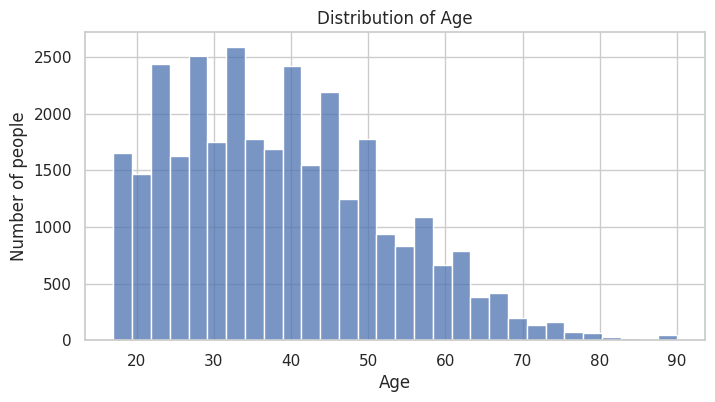

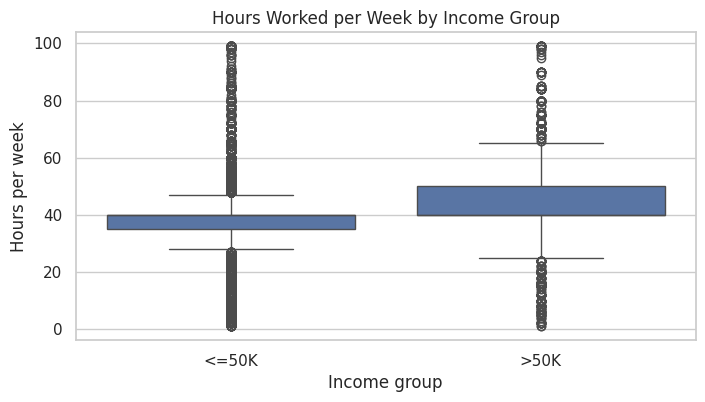

In [30]:
# Task 8.2: Histogram of age, and a box plot of hours_per_week by income.
plt.figure(figsize=(8, 4))
sns.histplot(clean["age"], bins=30)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of people")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x="income", y="hours_per_week", data=clean)
plt.title("Hours Worked per Week by Income Group")
plt.xlabel("Income group")
plt.ylabel("Hours per week")
plt.show()

Observation

The age histogram is skewed to the right: most people are between their 20s and 50s, with fewer older people. In the box plot, the box for the greater than $50K group sits higher than for the <=50K group, so high earners tend to work longer hours. Both groups have outlier dots at very short and very long weeks.

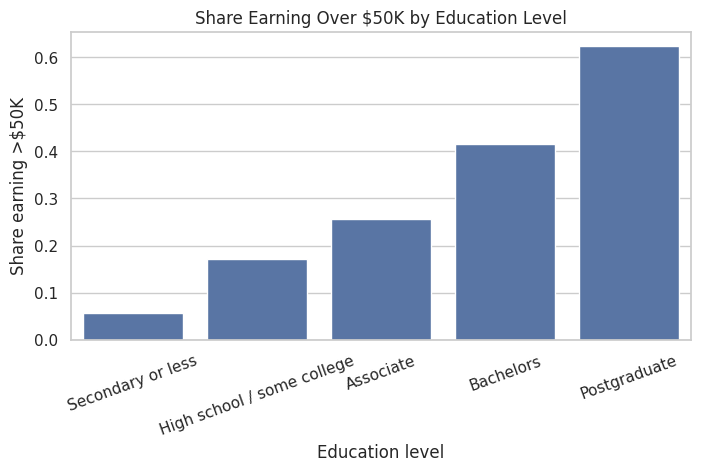

education_level
Secondary or less             0.057439
High school / some college    0.172142
Associate                     0.255615
Bachelors                     0.414908
Postgraduate                  0.622648
Name: high_income, dtype: float64


In [31]:
# Task 8.3: Bar chart of the high-income rate by education_level (ordered from lowest to highest education).
order = ["Secondary or less", "High school / some college", "Associate", "Bachelors", "Postgraduate"]
rate = clean.groupby("education_level")["high_income"].mean().reindex(order)
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.index, y=rate.values)
plt.title("Share Earning Over $50K by Education Level")
plt.xlabel("Education level")
plt.ylabel("Share earning >$50K")
plt.xticks(rotation=20)
plt.show()
print(rate)

Observation

1. The share earning above $50K rises at every education level, from 5.7% for “Secondary or less” to 62.3% for “Postgraduate”.

2. The biggest jumps come after Associate (25.6% to 41.5% for Bachelors, then 62.3% for Postgraduate).
3. People with a postgraduate degree earn above $50K about 11 times as often as people with secondary education or less (62.3% vs 5.7%).
4. Education is strongly associated with income here, though this alone doesn’t prove that education causes the higher earnings.

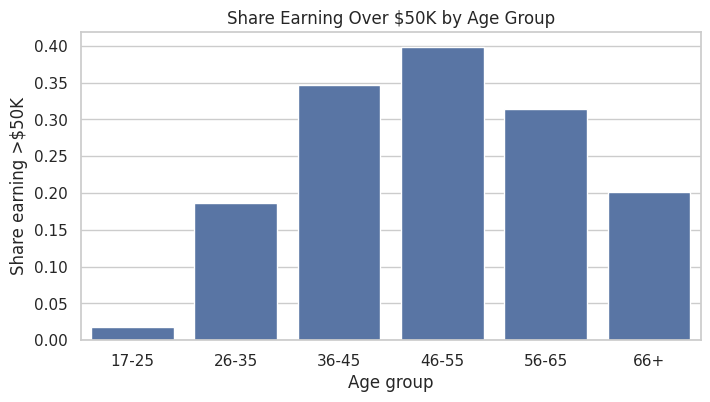

age_group
17-25    0.017812
26-35    0.186957
36-45    0.346284
46-55    0.398627
56-65    0.314910
66+      0.201383
Name: high_income, dtype: float64


In [32]:
# Task 8.4: Bar chart of the high-income rate by age_group. At what age is the rate highest?
rate = clean.groupby("age_group", observed=True)["high_income"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.index, y=rate.values)
plt.title("Share Earning Over $50K by Age Group")
plt.xlabel("Age group")
plt.ylabel("Share earning >$50K")
plt.show()
print(rate)

Observation

1. The share earning above $50K is highest in the 46-55 age group, at about 39.9%.
2. It rises steadily from 1.8% for ages 17-25 to 18.7% for 26-35 and 34.6% for 36-45.
3. After 55 it falls again, to 31.5% for 56-65 and 20.1% for 66+, which fits with people reducing work or retiring.
4. This suggests income grows with age and experience, so young people shouldn’t expect high earnings early in their careers.

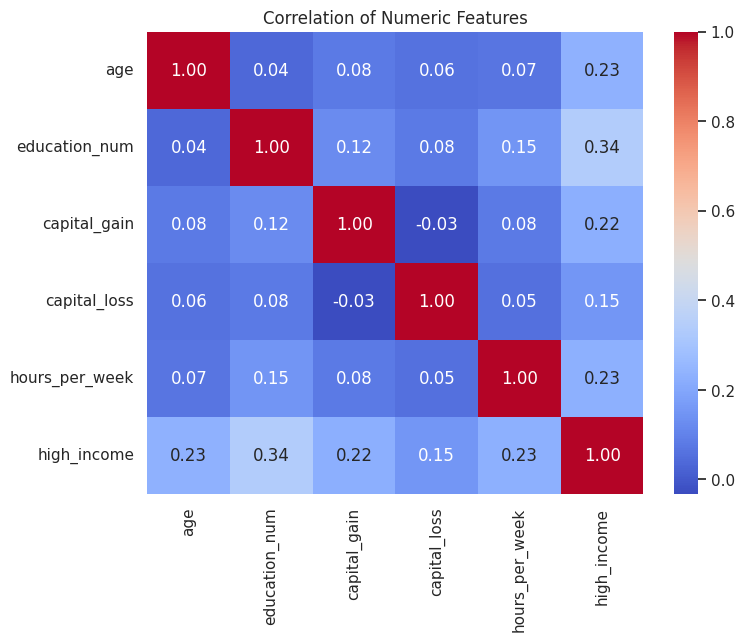

In [33]:
# Task 8.5: Correlation heatmap of the number columns (age, education_num, capital_gain,
# capital_loss, hours_per_week, high_income). Which feature has the strongest correlation with high_income?
num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week", "high_income"]
plt.figure(figsize=(8, 6))
sns.heatmap(clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of Numeric Features")
plt.show()

Observation

1. education_num has the strongest correlation with high_income, at 0.34.
The next strongest are age and hours_per_week (both 0.23), then capital_gain (0.22), and capital_loss is weakest at 0.15.

2. All the correlations with high_income are positive, so more education, older age, more hours and higher capital gains all go along with a higher chance of earning above $50K.

3. Even the strongest one, 0.34, is only a moderate relationship, so no single numeric feature explains income on its own.

4. The features are only weakly correlated with each other (mostly 0.03 to 0.15), so each adds somewhat separate information.

---
## Your findings (required)
In a text cell, write for the youth employment programme:
1. **Five findings**, each with a number (e.g. "People with a postgraduate degree earn >$50K about X% of the time, compared with Y% for…").

2. **Two pieces of advice** for young people, based on your findings.
3. **One limitation**: why might this 1994 US data not apply directly to young Nigerians today?
4. **Correlation vs causation:** married people earn >$50K far more often. Does marriage *cause* higher income? Explain in 2–3 sentences.

---
## Marking (50 marks)
| Step | Marks |
|---|---|
| 1. Problem defined, with 3 analytical questions | 4 |
| 2–4. Data loaded correctly with column names; understood and inspected | 8 |
| 5. All quality problems found, with summary table | 10 |
| 6. Cleaning done, each fix explained | 10 |
| 7. New columns, filter/sort, groupby, merge, pivot | 8 |
| 8. Statistics and 4 charts with titles, labels and observations | 6 |
| Findings, advice, limitation, causation answer | 4 |
| **Total** | **50** |

**Before you submit:** Runtime → Restart and run all. Make sure every cell runs without errors and every observation is written.

# **Findings**

Five findings from the data analysis

1. About 24% of people in the data earn more than 50k a year, and about 76% earn $50K or less.

2. Education has the strongest pattern. About 62% of people with a postgraduate degree earn above $50K, compared with only about 6% of those with secondary education or less.

3. The share rises at every education level: about 17% for high school or some college, 26% for an associate degree, 41% for a bachelor’s degree, and 62% for a postgraduate degree.

4. Age matters too. Only about 2% of people aged 17-25 earn above $50K, compared with about 40% of those aged 46-55, which is the highest share of any age group.
5. Most people have no investment income. The median capital gain is 0, while the mean is about 1,078, because a small number of people with large gains pull the average up.

**Two pieces of advice I would give**

1. Aim for a bachelor’s degree or higher, because the share earning above $50K goes up with each education level.

2. Be patient early in your career. Earnings grow with experience and peak in mid-career, so build skills in your 20s and 30s.

**One limitation**

1. This data is from the 1994 US census, so it may not apply to young Nigerians today. The economy, the cost of living, the value of $50K, the jobs available and the education system are all different. The data also leaves out things that matter in Nigeria today.

**Correlation vs causation**

Married people earn above $50K more often, but that doesn’t prove marriage causes higher income. Married people tend to be older, and we saw that income rises with age, so age could explain part of the link. Higher earners may also be more likely to marry, and two-income households can raise the numbers, so the relationship can run either way.